# 03. Thấu hiểu dữ liệu – EDA (Data Understanding)

Hai phần:
- **A. Kiểm toán bằng SQL** ngay trên PostgreSQL (bảng `raw_products`): dữ liệu đủ chưa, có trùng, thiếu, trường cá nhân hay trường lộ đáp án không. Các câu SQL nằm trong `sql/audit_queries.sql`, chạy được cả trong pgAdmin.
- **B. Khám phá bằng Python** (pandas, matplotlib, seaborn) trên bảng phẳng `data/processed/products.parquet` do notebook 02 tạo: thống kê mô tả, thiếu, trùng, ngoại lai, phân phối, tương quan, tính đại diện.

Cuối notebook là **danh sách vấn đề của dữ liệu** và cách xử lý ở notebook 04.

In [1]:
# Chạy từ thư mục gốc dự án để đọc được data/, sql/ và import src/
import os, sys
from pathlib import Path
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(root)
sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
GRADE_COLORS = {"a": "#038141", "b": "#85BB2F", "c": "#FECB02", "d": "#EE8100", "e": "#E63E11"}
FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

from src.db import query, load_queries
Q = load_queries("sql/audit_queries.sql")
list(Q)

['tong_quan',
 'nhan_goc',
 'dung_duoc',
 'hang_theo_nova',
 'ty_le_thieu',
 'so_thanh_phan',
 'the_taxonomy',
 'thuong_hieu',
 'quoc_gia',
 'truong_nhay_cam',
 'ma_trung_join']

## A. Kiểm toán dữ liệu thô bằng SQL

### A1. Tổng quan và mã vạch
Mã vạch phải giữ dạng **chuỗi**: nhiều mã bắt đầu bằng số 0, đổi sang số sẽ mất số 0 và ghép nhầm sản phẩm.

In [2]:
overview = query(Q["tong_quan"])
overview

,so_ban_ghi,so_ma_vach,ban_ghi_trung_ma,ma_bat_dau_bang_0,ma_co_ky_tu_la,ma_khong_phai_chuoi
0,30000,30000,0,10963,0,0


### A2. Nhãn gốc và số bản ghi dùng được (có nhãn A–E và có thành phần)

In [3]:
query(Q["nhan_goc"])

,nhan,so_ban_ghi
0,e,8519
1,d,7128
2,c,6502
3,a,4540
4,b,3309
5,(thiếu),2


In [4]:
usable = query(Q["dung_duoc"])
usable

,dung_duoc,co_nova,pct_co_nova
0,29998,27078,90.3


### A3. Hạng theo NOVA (GROUP BY + FILTER): sản phẩm siêu chế biến (NOVA 4) có hạng kém hơn không?

In [5]:
query(Q["hang_theo_nova"])

,hang,nova_1,nova_2,nova_3,nova_4,thieu_nova
0,a,1905,13,934,1152,536
1,b,639,114,682,1274,600
2,c,517,83,1367,4010,525
3,d,271,39,1723,4607,488
4,e,106,209,1199,6234,771


### A4. Tỷ lệ thiếu của các trường chính

In [6]:
missing_sql = query(Q["ty_le_thieu"])
missing_sql

,truong,pct_thieu
0,labels_tags,55.2
1,additives_tags,44.1
2,allergens_tags,38.6
3,pnns_groups_2,20.4
4,pnns_groups_1,19.9
5,brands_tags,14.9
6,nova_group,9.7
7,product_name,0.7
8,countries_tags,0.3
9,ingredients_tags,0.0


### A5. Số thành phần, thẻ đã chuẩn hóa, thương hiệu, quốc gia

In [7]:
query(Q["so_thanh_phan"])

,nho_nhat,trung_vi,trung_binh,lon_nhat,toi_da_1_thanh_phan,tren_150_thanh_phan
0,1,11.0,14.9,231,4011,19


In [8]:
taxonomy = query(Q["the_taxonomy"])
taxonomy

,so_the,pct_the_en
0,739875,94.8


In [9]:
brands = query(Q["thuong_hieu"])
brands

,thuong_hieu,so_ban_ghi,pct
0,(thiếu),4456,14.9
1,xx:U,307,1.0
2,xx:Carrefour,247,0.8
3,xx:auchan,229,0.8
4,xx:aldi,188,0.6
5,xx:coop,160,0.5
6,xx:nestle,151,0.5
7,xx:Casino,131,0.4
8,xx:marque-repere,115,0.4
9,xx:leader-price,103,0.3


In [10]:
query(Q["quoc_gia"])

,quoc_gia,so_ban_ghi,pct
0,en:united-states,11326,37.8
1,en:france,8661,28.9
2,en:germany,2972,9.9
3,en:united-kingdom,1318,4.4
4,en:spain,1255,4.2
5,en:italy,1059,3.5
6,en:switzerland,749,2.5
7,en:world,709,2.4
8,en:belgium,706,2.4
9,en:netherlands,640,2.1


### A6. Trường cá nhân và trường lộ đáp án
Không được có trường cá nhân (đạo đức dữ liệu). Các trường bắt đầu bằng `nutri` (bảng dinh dưỡng, điểm, nhãn) **có** trong dữ liệu thô nhưng chỉ được dùng làm nhãn y hoặc để EDA, không bao giờ làm đặc trưng.

In [11]:
keys = query(Q["truong_nhay_cam"])
keys[keys["loai"] != "dùng được"]

,truong,so_ban_ghi,loai
20,nutriments,30000,RÒ RỈ NHÃN: không làm đặc trưng
21,nutriscore_grade,30000,RÒ RỈ NHÃN: không làm đặc trưng
22,nutriscore_score,30000,RÒ RỈ NHÃN: không làm đặc trưng


### A7. Tìm mã vạch trùng bằng JOIN bảng với chính nó

In [12]:
query(Q["ma_trung_join"])

,code,id_a,id_b,tep_a,tep_b


### A8. Đối chiếu với yêu cầu dữ liệu ở notebook 01

In [13]:
grades = query(Q["nhan_goc"]).set_index("nhan")["so_ban_ghi"]
pii = keys[keys["loai"].str.startswith("CÁ NHÂN")]
checks = pd.DataFrame([
    ("Số bản ghi dùng được >= 10.000", int(usable.loc[0, "dung_duoc"]), usable.loc[0, "dung_duoc"] >= 10_000),
    ("Hạng ít nhất >= 100 mẫu", int(grades[list("abcde")].min()), grades[list("abcde")].min() >= 100),
    ("NOVA phủ >= 50%", float(usable.loc[0, "pct_co_nova"]), usable.loc[0, "pct_co_nova"] >= 50),
    ("Thẻ thành phần có tiền tố en: >= 90%", float(taxonomy.loc[0, "pct_the_en"]), taxonomy.loc[0, "pct_the_en"] >= 90),
    ("Thương hiệu lớn nhất <= 10%", float(brands.loc[brands["thuong_hieu"] != "(thiếu)", "pct"].max()),
     brands.loc[brands["thuong_hieu"] != "(thiếu)", "pct"].max() <= 10),
    ("Không có trường cá nhân", len(pii), len(pii) == 0),
    ("Không trùng mã vạch", int(overview.loc[0, "ban_ghi_trung_ma"]), overview.loc[0, "ban_ghi_trung_ma"] == 0),
], columns=["Yêu cầu", "Giá trị", "Đạt"])
checks

,Yêu cầu,Giá trị,Đạt
0,Số bản ghi dùng được >= 10.000,29998.0,True
1,Hạng ít nhất >= 100 mẫu,3309.0,True
2,NOVA phủ >= 50%,90.3,True
3,Thẻ thành phần có tiền tố en: >= 90%,94.8,True
4,Thương hiệu lớn nhất <= 10%,1.0,True
5,Không có trường cá nhân,0.0,True
6,Không trùng mã vạch,0.0,True


## B. Khám phá bằng Python

### B1. Kích thước và kiểu dữ liệu

In [14]:
df = pd.read_parquet("data/processed/products.parquet")
df["grade"] = df["nutriscore_grade"]                       # viết tắt cho gọn
print(df.shape)
df.dtypes.to_frame("kiểu").T

(30000, 30)


,row_id,code,product_name,brands_tags,countries_tags,categories_tags,ingredients_tags,ingredients_analysis_tags,additives_tags,allergens_tags,...,nutriscore_grade,nutriscore_score,energy_kcal_100g,fat_100g,saturated_fat_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,grade
kiểu,int64,str,str,object,object,object,object,object,object,object,...,str,float64,float64,float64,float64,float64,float64,float64,float64,str


### B2. Thống kê mô tả (mean, median, min, max, độ lệch chuẩn)
Cột dinh dưỡng và điểm Nutri-Score có ở đây **chỉ để hiểu dữ liệu**; chúng sẽ bị tách khỏi đặc trưng.

In [15]:
NUM = ["ingredients_n", "additives_n", "ingredients_from_palm_oil_n", "nova_group", "nutriscore_score",
       "energy_kcal_100g", "sugars_100g", "saturated_fat_100g", "salt_100g", "fiber_100g", "proteins_100g"]
desc = df[NUM].describe().T
desc.insert(2, "median", df[NUM].median())
desc.round(2)

,count,mean,median,std,min,25%,50%,75%,max
ingredients_n,30000.0,14.86,11.00,15.54,1.00,4.00,11.00,20.00,231.0
additives_n,30000.0,1.92,1.00,2.80,0.00,0.00,1.00,3.00,38.0
ingredients_from_palm_oil_n,22286.0,0.02,0.00,0.13,0.00,0.00,0.00,0.00,2.0
nova_group,27079.0,3.37,4.00,1.01,1.00,3.00,4.00,4.00,4.0
nutriscore_score,29998.0,10.90,11.00,10.45,-17.00,2.00,11.00,19.00,55.0
energy_kcal_100g,29579.0,293.61,255.00,333.76,0.00,94.00,255.00,407.41,10000.0
sugars_100g,29418.0,14.97,4.42,28.39,0.00,1.00,4.42,20.00,1110.0
saturated_fat_100g,28759.0,5.35,1.80,10.46,0.00,0.10,1.80,7.14,532.0
salt_100g,29690.0,1.47,0.40,21.14,0.00,0.04,0.40,1.20,2100.0
fiber_100g,23507.0,2.93,1.40,6.45,-0.05,0.00,1.40,3.60,512.0


Nhận xét:
- Trung vị 11 thành phần, 1 phụ gia; trung bình lớn hơn trung vị → phân phối **lệch phải**.
- NOVA trung vị 4: phần lớn sản phẩm là siêu chế biến.
- Bảng dinh dưỡng có giá trị **phi lý** (đường 1.110 g/100 g, muối 2.100 g/100 g, đạm âm): lỗi nhập liệu của cộng đồng. Các cột này không làm đặc trưng nên không ảnh hưởng mô hình, nhưng cho thấy dữ liệu cộng đồng cần được kiểm tra trước khi tin.

### B3. Giá trị thiếu
Với cột danh sách thẻ, danh sách rỗng `[]` cũng tính là thiếu.

In [16]:
def is_missing(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return True
    return hasattr(v, "__len__") and not isinstance(v, str) and len(v) == 0

FEATURE_LIKE = ["product_name", "brands_tags", "countries_tags", "categories_tags", "pnns_groups_1", "pnns_groups_2",
                "ingredients_tags", "ingredients_n", "additives_tags", "allergens_tags", "labels_tags",
                "ingredients_analysis_tags", "nova_group", "nutriscore_grade"]
missing = (df[FEATURE_LIKE].map(is_missing).mean() * 100).round(1).sort_values(ascending=False)
missing.to_frame("% thiếu").T

,labels_tags,additives_tags,allergens_tags,pnns_groups_2,pnns_groups_1,brands_tags,nova_group,product_name,countries_tags,categories_tags,ingredients_tags,ingredients_n,ingredients_analysis_tags,nutriscore_grade
% thiếu,55.2,44.1,38.6,20.4,19.9,14.9,9.7,0.7,0.3,0.0,0.0,0.0,0.0,0.0


Nhận xét: thiếu nhiều ở `labels_tags`, `additives_tags` (nhiều sản phẩm thật sự không có nhãn hay phụ gia, nên "thiếu" ở đây thường nghĩa là "không có"), `pnns_groups_1/2` khoảng 20%, thương hiệu 15%, NOVA 10%. Chỉ 2 dòng thiếu nhãn.

### B4. Dữ liệu trùng
Không trùng mã vạch (đã thấy ở A7), nhưng có thể có **cùng một sản phẩm** đăng nhiều lần dưới mã khác nhau: cùng thương hiệu, cùng tên, cùng danh sách thành phần. Nếu một bản ở train và bản kia ở test thì mô hình "học thuộc" được đáp án.

In [17]:
from src.cleaning import clean_brands, content_key, normalize_name

brand = df["brands_tags"].map(clean_brands).map(lambda b: b[0] if b else None)
keys_ = pd.Series([content_key(b, normalize_name(n), list(i) if i is not None else None)
                   for b, n, i in zip(brand, df["product_name"], df["ingredients_tags"])])
print("Sản phẩm trùng nội dung (thương hiệu + tên + thành phần):", int((keys_.notna() & keys_.duplicated()).sum()))

Sản phẩm trùng nội dung (thương hiệu + tên + thành phần): 75


### B5. Ngoại lai (outlier)
Dùng quy tắc IQR: giá trị > Q3 + 1,5·IQR là ngoại lai. Với số thành phần, phần lớn "ngoại lai" theo IQR là sản phẩm thật nhiều thành phần (món ăn chế biến sẵn) nên **giữ lại**; chỉ những giá trị phi lý (> 150 thành phần) mới là lỗi nhập liệu.

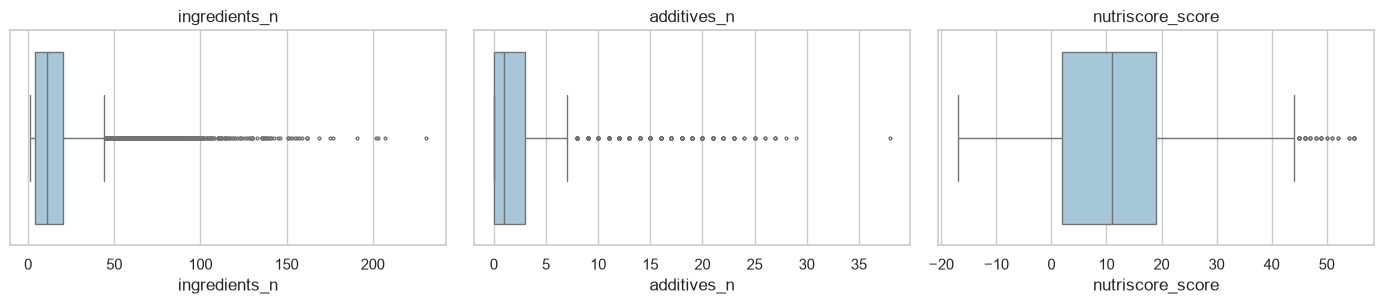

ingredients_n: Q1=4, Q3=20, ngưỡng IQR=44
Số sản phẩm vượt ngưỡng IQR: 1372
Số sản phẩm > 150 thành phần (lỗi nhập liệu): 19
Số sản phẩm <= 1 thành phần (mật ong, dầu ô liu... vẫn hợp lệ): 4011


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, col in zip(axes, ["ingredients_n", "additives_n", "nutriscore_score"]):
    sns.boxplot(x=df[col], ax=ax, color="#9ecae1", fliersize=2)
    ax.set_title(col)
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_03_boxplot_ngoai_lai.png", dpi=110); plt.show()

q1, q3 = df["ingredients_n"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"ingredients_n: Q1={q1:.0f}, Q3={q3:.0f}, ngưỡng IQR={upper:.0f}")
print("Số sản phẩm vượt ngưỡng IQR:", int((df["ingredients_n"] > upper).sum()))
print("Số sản phẩm > 150 thành phần (lỗi nhập liệu):", int((df["ingredients_n"] > 150).sum()))
print("Số sản phẩm <= 1 thành phần (mật ong, dầu ô liu... vẫn hợp lệ):", int((df["ingredients_n"] <= 1).sum()))

### B6. Phân phối nhãn (biến cần dự đoán)

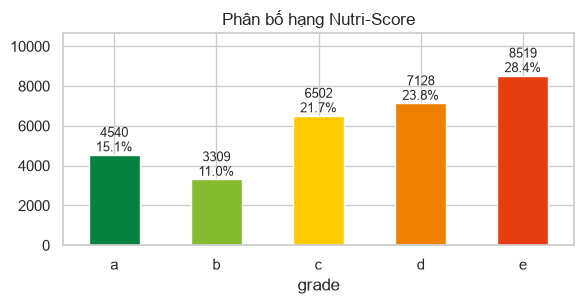

E / B = 2.57


In [19]:
lab = df[df["grade"].notna()].copy()
counts = lab["grade"].value_counts().reindex(list("abcde"))
ax = counts.plot.bar(color=[GRADE_COLORS[g] for g in counts.index], figsize=(6, 3.2), rot=0)
for i, v in enumerate(counts):
    ax.text(i, v, f"{v}\n{v / len(lab):.1%}", ha="center", va="bottom", fontsize=9)
ax.set_title("Phân bố hạng Nutri-Score"); ax.set_ylim(0, counts.max() * 1.25)
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_01_phan_bo_nhan.png", dpi=110); plt.show()
print("E / B =", round(counts["e"] / counts["b"], 2))

Lệch vừa phải: E nhiều nhất, B ít nhất (khoảng 2,6 lần). Không cần SMOTE; dùng **trọng số lớp** (`class_weight="balanced"`) và chỉ số **Macro-F1** để hạng B không bị bỏ quên.

### B7. Mẫu có đại diện cho toàn bộ Open Food Facts không?
So phân bố hạng của mẫu 30.000 với toàn bộ 1,42 triệu sản phẩm có hạng trong bản dump.

In [20]:
import duckdb
full = duckdb.sql('''SELECT lower(nutriscore_grade) AS grade, count(*) AS n FROM read_parquet('data/external/food.parquet')
                     WHERE lower(nutriscore_grade) IN ('a','b','c','d','e') AND len(ingredients_tags) > 0
                     GROUP BY 1''').df().set_index("grade")["n"]
pd.DataFrame({"Mẫu 30.000 (%)": (counts / counts.sum() * 100).round(1),
              "Toàn bộ dump (%)": (full / full.sum() * 100).reindex(list("abcde")).round(1)}).T

grade,a,b,c,d,e
Mẫu 30.000 (%),15.1,11.0,21.7,23.8,28.4
Toàn bộ dump (%),15.3,10.9,21.3,23.9,28.5


Phân bố gần như trùng khớp (chênh dưới 0,5 điểm %), nên mẫu ngẫu nhiên **đại diện** cho tập sản phẩm có nhãn. Hạn chế: sản phẩm *thiếu* dinh dưỡng ngoài đời có thể khác loại với sản phẩm có nhãn (ghi ở phần hạn chế).

### B8. Phân phối các biến số theo hạng (histogram)

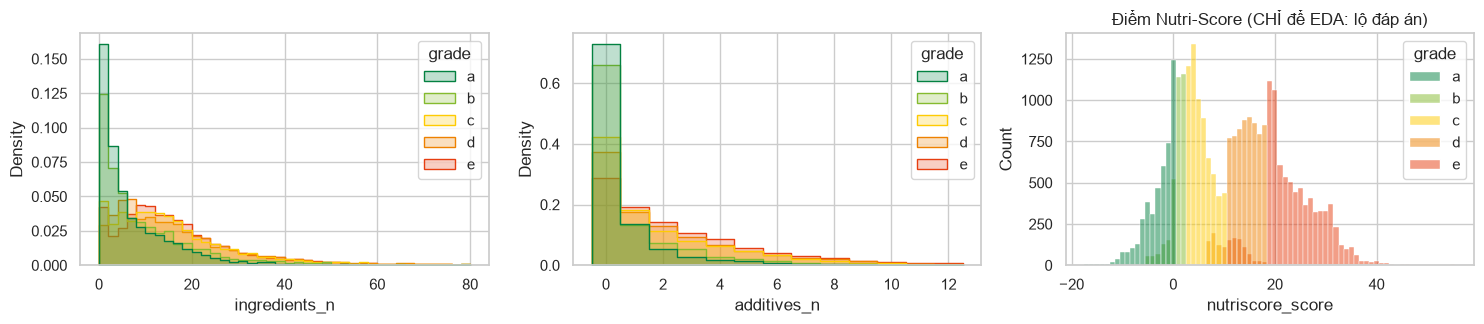

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
sns.histplot(data=lab, x="ingredients_n", hue="grade", hue_order=list("abcde"), palette=GRADE_COLORS,
             bins=40, binrange=(0, 80), element="step", stat="density", common_norm=False, ax=axes[0])
sns.histplot(data=lab, x="additives_n", hue="grade", hue_order=list("abcde"), palette=GRADE_COLORS,
             discrete=True, binrange=(0, 12), element="step", stat="density", common_norm=False, ax=axes[1])
sns.histplot(data=lab, x="nutriscore_score", hue="grade", hue_order=list("abcde"), palette=GRADE_COLORS,
             discrete=True, ax=axes[2])
axes[2].set_title("Điểm Nutri-Score (CHỈ để EDA: lộ đáp án)")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_02_histogram.png", dpi=110); plt.show()

- Số thành phần và số phụ gia lệch phải mạnh (đuôi dài) → khi làm đặc trưng sẽ lấy `log(1 + x)` rồi chuẩn hóa.
- Hạng D/E có nhiều phụ gia hơn một chút, nhưng các phân phối **chồng lên nhau rất nhiều**: một biến đếm riêng lẻ không đủ để đoán hạng.
- Điểm Nutri-Score tách các hạng gọn gàng theo ngưỡng (vì hạng được tính từ điểm), nên điểm là **đáp án**, tuyệt đối không làm đặc trưng.

### B9. Tương quan giữa các biến
Dùng tương quan Spearman (hợp với biến lệch và thang thứ tự A < B < … < E).

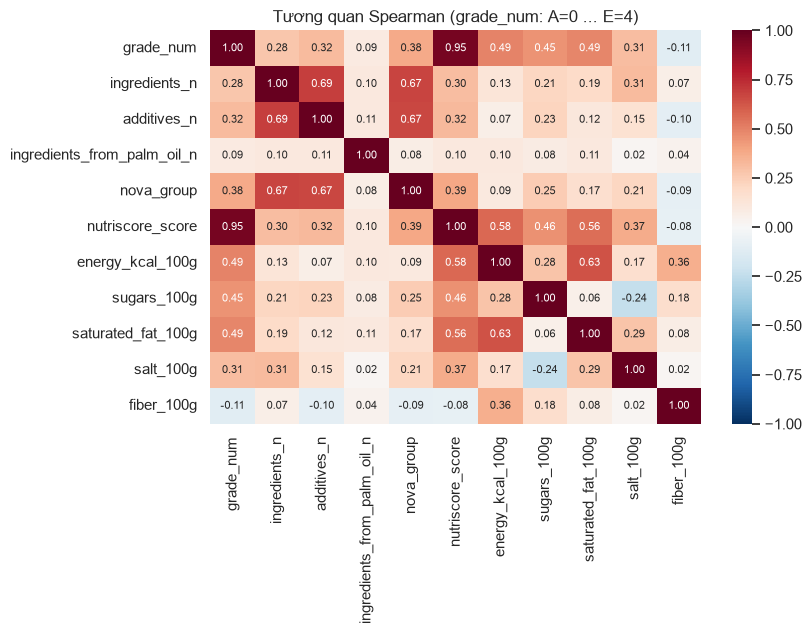

,nutriscore_score,energy_kcal_100g,saturated_fat_100g,sugars_100g,nova_group,additives_n,salt_100g,ingredients_n,ingredients_from_palm_oil_n,fiber_100g
Spearman với hạng,0.95,0.49,0.49,0.45,0.38,0.32,0.31,0.28,0.09,-0.11


In [22]:
lab["grade_num"] = lab["grade"].map({g: i for i, g in enumerate("abcde")})
CORR = ["grade_num", "ingredients_n", "additives_n", "ingredients_from_palm_oil_n", "nova_group",
        "nutriscore_score", "energy_kcal_100g", "sugars_100g", "saturated_fat_100g", "salt_100g", "fiber_100g"]
corr = lab[CORR].corr(method="spearman")
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Tương quan Spearman (grade_num: A=0 ... E=4)")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_04_tuong_quan.png", dpi=110); plt.show()
corr["grade_num"].drop("grade_num").sort_values(ascending=False).round(2).to_frame("Spearman với hạng").T

- Điểm Nutri-Score tương quan gần 1 với hạng, đường/chất béo bão hòa/năng lượng cũng cao: đây là **rò rỉ nhãn**, vì hạng được tính từ chính các con số này. Sản phẩm thiếu bảng dinh dưỡng không có chúng → **loại khỏi đặc trưng**.
- Trong các biến được phép dùng, NOVA (khoảng 0,38), số phụ gia (0,32) và số thành phần (0,28) chỉ tương quan dương **vừa phải** với hạng. Chừng đó chưa đủ: cần thông tin **nội dung** (thành phần nào, danh mục nào) chứ không chỉ số lượng.

### B10. Hạng theo quốc gia

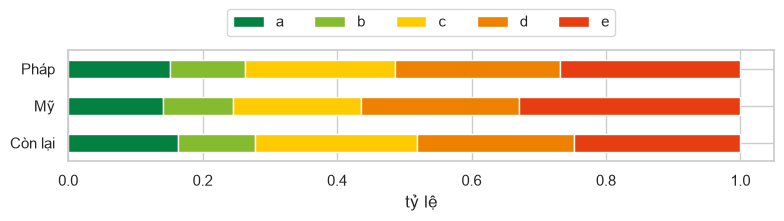

grade,a,b,c,d,e
countries_tags,,,,,
Còn lại,16.3,11.6,24.0,23.4,24.7
Mỹ,14.0,10.5,19.1,23.4,33.0
Pháp,15.2,11.1,22.3,24.6,26.8


In [23]:
def country_group(tags):
    tags = list(tags) if tags is not None else []
    return "Pháp" if "en:france" in tags else "Mỹ" if "en:united-states" in tags else "Còn lại"

share = pd.crosstab(lab["countries_tags"].map(country_group), lab["grade"], normalize="index")
ax = share.plot.barh(stacked=True, color=[GRADE_COLORS[g] for g in share.columns], figsize=(8, 2.6))
ax.set_xlabel("tỷ lệ"); ax.legend(ncol=5, bbox_to_anchor=(0.5, 1.25), loc="center"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_05_nhan_theo_quoc_gia.png", dpi=110); plt.show()
(share * 100).round(1)

Phân bố hạng khác nhau theo thị trường (Mỹ nhiều E hơn), nên mô hình phải được **báo cáo riêng cho Pháp, Mỹ và nhóm còn lại**, và quốc gia là một đặc trưng.

### B11. Hạng theo nhóm danh mục: danh mục mạnh đến đâu?

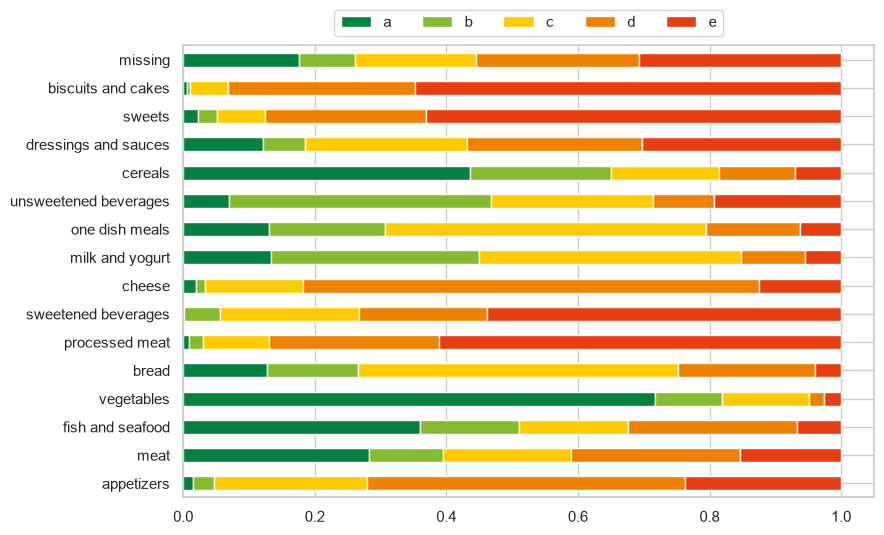

Đúng trên sản phẩm CÓ nhóm: 0.506
Đúng trên sản phẩm THIẾU nhóm: 0.307
Đúng trên toàn bộ: 0.465


In [24]:
lab["pnns2"] = lab["pnns_groups_2"].fillna("missing")
top = lab["pnns2"].value_counts().head(16).index
tab = pd.crosstab(lab.loc[lab["pnns2"].isin(top), "pnns2"], lab["grade"], normalize="index").loc[top]
ax = tab.plot.barh(stacked=True, color=[GRADE_COLORS[g] for g in tab.columns], figsize=(9, 5.5))
ax.invert_yaxis(); ax.set_ylabel(""); ax.legend(ncol=5, bbox_to_anchor=(0.5, 1.05), loc="center")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_06_nhan_theo_danh_muc.png", dpi=110); plt.show()

# Nếu chỉ đoán "hạng phổ biến nhất của nhóm" thì đúng bao nhiêu? (học và đo trên cùng dữ liệu, chỉ để mô tả)
majority_right = lab.groupby("pnns2")["grade"].transform(lambda s: s.value_counts().index[0]) == lab["grade"]
print("Đúng trên sản phẩm CÓ nhóm:", round(majority_right[lab["pnns2"] != "missing"].mean(), 3))
print("Đúng trên sản phẩm THIẾU nhóm:", round(majority_right[lab["pnns2"] == "missing"].mean(), 3))
print("Đúng trên toàn bộ:", round(majority_right.mean(), 3))

- Danh mục rất mạnh: nước uống, trái cây/rau gần như toàn A; đồ ngọt, đồ uống có đường gần như toàn D/E.
- Một quy tắc đơn giản "đoán hạng phổ biến nhất của nhóm" đúng khoảng 50% trên sản phẩm có nhóm, nhưng chỉ khoảng 31% trên 20% sản phẩm **thiếu nhóm**. Quy tắc này sẽ là **đường cơ sở** mà mô hình phải vượt (đo đúng cách bằng đánh giá chéo ở notebook 05).
- Nhóm "missing" cần được giữ làm một giá trị riêng, và nên dùng thêm `categories_tags` chi tiết.

### B12. Thẻ thành phần: đuôi dài

Số thẻ thành phần khác nhau: 55647
Thẻ có ở >= 20 sản phẩm: 1489 thẻ, chiếm 89.7% lượt xuất hiện
Thẻ có ở >= 100 sản phẩm: 629 thẻ, chiếm 84.5% lượt xuất hiện


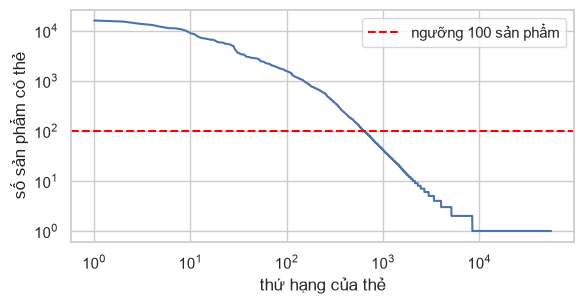

In [25]:
from collections import Counter
tag_counts = Counter(t for tags in lab["ingredients_tags"] for t in set(tags))
freq = np.array(sorted(tag_counts.values(), reverse=True))
print("Số thẻ thành phần khác nhau:", len(freq))
for k in (20, 100):
    print(f"Thẻ có ở >= {k} sản phẩm: {(freq >= k).sum()} thẻ, chiếm {freq[freq >= k].sum() / freq.sum():.1%} lượt xuất hiện")

plt.figure(figsize=(6, 3.2))
plt.loglog(np.arange(1, len(freq) + 1), freq)
plt.axhline(100, color="red", ls="--", label="ngưỡng 100 sản phẩm")
plt.xlabel("thứ hạng của thẻ"); plt.ylabel("số sản phẩm có thẻ"); plt.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_07_duoi_dai_thanh_phan.png", dpi=110); plt.show()

Vài trăm thẻ phổ biến chiếm phần lớn lượt xuất hiện; hàng chục nghìn thẻ còn lại rất hiếm (lỗi chính tả, chưa dịch). → Chỉ giữ thẻ có ở **≥ 100 sản phẩm** làm cột (ngưỡng `min_freq`); thẻ hiếm bỏ đi để mô hình không học thuộc nhiễu.

### B13. Thành phần và phụ gia nào đi kèm hạng D/E? (lift)
`lift = P(D hoặc E | có thẻ) / P(D hoặc E)`. Lift 2 nghĩa là sản phẩm có thẻ đó hay bị D/E gấp đôi mức chung. Chỉ xét thẻ có ở ≥ 200 sản phẩm.

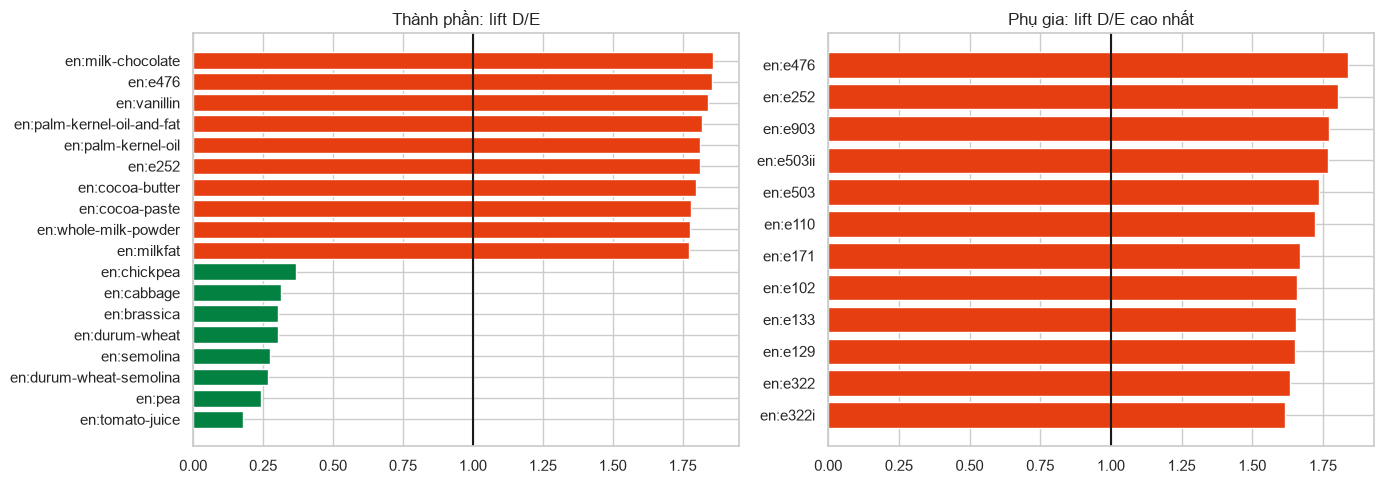

Tỷ lệ D/E chung: 0.522


,thẻ,số sản phẩm,lift D/E
204,en:milkfat,1032,1.77
150,en:whole-milk-powder,889,1.78
159,en:cocoa-paste,1756,1.78
157,en:cocoa-butter,2222,1.80
403,en:e252,216,1.81
296,en:palm-kernel-oil,624,1.81
295,en:palm-kernel-oil-and-fat,680,1.82
329,en:vanillin,250,1.84
280,en:e476,214,1.85
327,en:milk-chocolate,461,1.86


In [26]:
bad = lab["grade"].isin(["d", "e"])
base = bad.mean()

def lift_table(col, min_count=200):
    rows = []
    for tag, n in Counter(t for tags in lab[col] if tags is not None for t in set(tags)).items():
        if n >= min_count:
            has = lab[col].map(lambda tags: tags is not None and tag in tags)
            rows.append((tag, n, bad[has].mean() / base))
    return pd.DataFrame(rows, columns=["thẻ", "số sản phẩm", "lift D/E"]).sort_values("lift D/E")

lift_ing = lift_table("ingredients_tags")
lift_add = lift_table("additives_tags")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
show = pd.concat([lift_ing.head(8), lift_ing.tail(10)])
axes[0].barh(show["thẻ"], show["lift D/E"], color=np.where(show["lift D/E"] > 1, "#E63E11", "#038141"))
axes[0].axvline(1, color="k"); axes[0].set_title("Thành phần: lift D/E")
show = lift_add.tail(12)
axes[1].barh(show["thẻ"], show["lift D/E"], color="#E63E11"); axes[1].axvline(1, color="k")
axes[1].set_title("Phụ gia: lift D/E cao nhất")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_08_lift_thanh_phan_phu_gia.png", dpi=110); plt.show()
print("Tỷ lệ D/E chung:", round(base, 3))
lift_ing.tail(10).round(2)

Thành phần kéo về D/E: các thẻ liên quan **đường, sô-cô-la, bơ ca cao, dầu cọ, kem, pho mát, muối**; kéo về A/B: rau, đậu, nước, ngũ cốc nguyên hạt. Phụ gia có lift cao là chất tạo màu, chất nhũ hóa thường gặp trong bánh kẹo. Đây là gợi ý ban đầu cho câu hỏi nghiên cứu 2; notebook 05 kiểm tra lại bằng mô hình.

### B14. NOVA và Nutri-Score

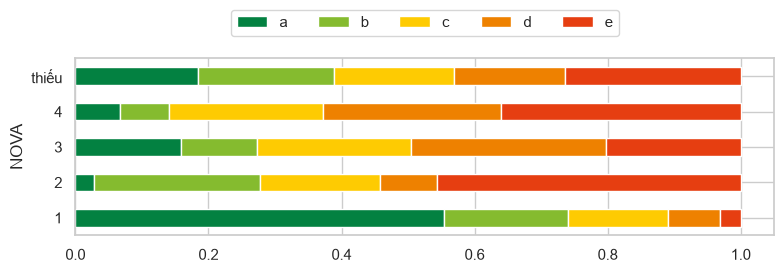

Chi-bình phương = 7323, p = 0.0e+00, Cramér's V = 0.25


In [27]:
from scipy.stats import chi2_contingency

nova_tab = pd.crosstab(lab["nova_group"].fillna(0).astype(int).replace(0, "thiếu").astype(str), lab["grade"])
chi2, p, dof, _ = chi2_contingency(nova_tab)
cramers_v = np.sqrt(chi2 / (nova_tab.to_numpy().sum() * (min(nova_tab.shape) - 1)))
share = nova_tab.div(nova_tab.sum(axis=1), axis=0)
ax = share.plot.barh(stacked=True, color=[GRADE_COLORS[g] for g in share.columns], figsize=(8, 3))
ax.set_ylabel("NOVA"); ax.legend(ncol=5, bbox_to_anchor=(0.5, 1.2), loc="center")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_09_nova_vs_nutriscore.png", dpi=110); plt.show()
print(f"Chi-bình phương = {chi2:.0f}, p = {p:.1e}, Cramér's V = {cramers_v:.2f}")

NOVA 1 (thực phẩm thô) phần lớn A/B; NOVA 4 (siêu chế biến) phần lớn D/E. Liên hệ có ý nghĩa thống kê nhưng **chỉ ở mức vừa** (Cramér's V khoảng 0,25): NOVA đo mức chế biến, Nutri-Score đo dinh dưỡng, hai khái niệm khác nhau. NOVA là đặc trưng hữu ích nhưng không thay được thành phần.

### B15. Thẻ trên bao bì làm lộ đáp án
`labels_tags` chứa cả **logo Nutri-Score in trên bao bì** (`en:nutriscore-grade-a`...), Health Star Rating, nhãn cảnh báo "exceso" của Mỹ Latinh. Đó là đáp án hoặc tóm tắt của bảng dinh dưỡng.

In [28]:
from src.cleaning import is_leaky_label

leaky = lab["labels_tags"].map(lambda tags: [t for t in (tags if tags is not None else []) if is_leaky_label(t)])
print("Sản phẩm có thẻ lộ đáp án:", int((leaky.str.len() > 0).sum()))
print(Counter(t for tags in leaky for t in tags).most_common(8))

logo = lab["labels_tags"].map(lambda tags: next((t[-1] for t in (tags if tags is not None else [])
                                                 if t.startswith("en:nutriscore-grade-") and t[-1] in "abcde"), None))
print("Logo trên bao bì trùng đúng hạng:", f"{(logo == lab['grade'])[logo.notna()].mean():.0%}",
      "trên", int(logo.notna().sum()), "sản phẩm có logo")
pd.crosstab(logo.rename("logo trên bao bì"), lab["grade"])

Sản phẩm có thẻ lộ đáp án: 2263
[('en:nutriscore', 2104), ('en:nutriscore-grade-a', 565), ('en:nutriscore-grade-c', 396), ('en:nutriscore-grade-d', 352), ('en:nutriscore-grade-b', 329), ('en:nutriscore-grade-e', 209), ('en:health-star-rating', 74), ('en:keyhole', 34)]
Logo trên bao bì trùng đúng hạng: 61% trên 1802 sản phẩm có logo


grade,a,b,c,d,e
logo trên bao bì,,,,,
a,346,133,78,4,4
b,30,107,166,15,5
c,3,14,214,128,12
d,0,1,20,233,82
e,0,2,1,9,195


Logo trùng đúng hạng ở khoảng 61% sản phẩm có logo, và gần như luôn lệch tối đa 1 hạng (logo in theo công thức cũ, nhãn hiện tại theo công thức 2023). Nếu để nguyên, mô hình sẽ "nhìn đáp án" → notebook 04 **xóa các thẻ này** khỏi `labels_tags` và `categories_tags` (giữ sản phẩm) và kiểm tra lại bằng `assert_no_leaky_values`.

## Tóm tắt: vấn đề của dữ liệu và cách xử lý

| # | Vấn đề phát hiện | Bằng chứng | Xử lý ở notebook 04 |
|---|---|---|---|
| 1 | Cột dinh dưỡng, điểm Nutri-Score lộ đáp án | B9: Spearman với hạng rất cao | Tách khỏi bảng đặc trưng; `assert_no_leakage` chặn theo tên cột |
| 2 | Logo Nutri-Score, Health Star, "exceso" trong `labels_tags` | B15 | Xóa thẻ, giữ dòng; kiểm tra lại theo **giá trị** |
| 3 | 2 dòng thiếu nhãn | A2 | Loại |
| 4 | Sản phẩm > 150 thành phần (lỗi nhập liệu) | B5 | Loại; sản phẩm ≤ 1 thành phần chỉ gắn cờ (vẫn hợp lệ) |
| 5 | Cùng sản phẩm đăng nhiều mã | B4 | Loại trùng theo thương hiệu + tên + thành phần |
| 6 | Thương hiệu viết nhiều kiểu (`xx:Carrefour`, `carrefour`) | A5 | Chuẩn hóa (bỏ dấu, chữ thường); dùng làm **nhóm** khi chia dữ liệu |
| 7 | Thiếu `pnns_groups` (~20%), NOVA (~10%), thương hiệu (~15%) | A4, B3 | Giá trị riêng "missing" (thiếu cũng là thông tin); số đếm thiếu → trung vị |
| 8 | Biến đếm lệch phải | B8 | `log(1+x)` + chuẩn hóa (StandardScaler) |
| 9 | Hàng chục nghìn thẻ hiếm | B12 | Chỉ giữ thẻ có ở ≥ 100 sản phẩm (học trên tập huấn luyện) |
| 10 | Mất cân bằng hạng vừa phải (E/B ≈ 2,6) | B6 | Trọng số lớp + Macro-F1 |
| 11 | Hạng khác nhau theo quốc gia | B10 | Đặc trưng quốc gia; báo cáo riêng Pháp / Mỹ / còn lại |
| 12 | Sản phẩm cùng hãng rất giống nhau | A5 | Chia train/test theo thương hiệu (GroupKFold) |
| 13 | `en:world` không phải quốc gia | A5 | Bỏ thẻ |